<a href="https://colab.research.google.com/github/Najla-Nuricia/PemMes_244107020091_Najla/blob/main/JS10/JS10_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
	from pathlib import Path
	import numpy as np
	import matplotlib.pyplot as plt
	import cv2

	from skimage.feature import hog
	from sklearn.preprocessing import StandardScaler
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import confusion_matrix, classification_report

	import tensorflow as tf
	from tensorflow.keras import layers, models

In [3]:
import os
import zipfile
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Extract ZIP
zip_path = "/content/drive/MyDrive/images.zip"
extract_path = "/content/images"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# 3. Check folder structure
for root, dirs, files in os.walk(extract_path):
    print(root, ":", len(files), "files")

# 4. Load images and labels
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []

    for folder in p.iterdir():
        if not folder.is_dir() or folder.name == "__MACOSX":
            continue

        label = folder.name

        for file in folder.rglob('*'):
            if file.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
                continue

            img = cv2.imread(str(file))

            if img is None:
                continue

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))

    return img_list

# 5. Dataset directory
train_dir = "/content/images/images/training"
test_dir = "/content/images/images/test"

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

# 6. Check dataset
print("\nTotal training images:", len(train_img))
print("Total testing images:", len(test_img))

print("Training labels:", set(label for _, label in train_img))
print("Testing labels:", set(label for _, label in test_img))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/images : 0 files
/content/images/images : 0 files
/content/images/images/test : 0 files
/content/images/images/test/night : 80 files
/content/images/images/test/day : 80 files
/content/images/images/training : 0 files
/content/images/images/training/night : 120 files
/content/images/images/training/day : 120 files
/content/images/__MACOSX : 1 files
/content/images/__MACOSX/images : 2 files
/content/images/__MACOSX/images/test : 2 files
/content/images/__MACOSX/images/test/night : 80 files
/content/images/__MACOSX/images/test/day : 80 files
/content/images/__MACOSX/images/training : 2 files
/content/images/__MACOSX/images/training/night : 120 files
/content/images/__MACOSX/images/training/day : 120 files

Total training images: 240
Total testing images: 160
Training labels: {'night', 'day'}
Testing labels: {'night', 'day'}


In [9]:


# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        if not folder.is_dir():
            continue
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "images/images/training/"
test_dir  = "images/images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print("Jumlah data latih:", len(train_img))
print("Jumlah data test :", len(test_img))



Jumlah data latih: 240
Jumlah data test : 160


In [12]:
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []

    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))

    return np.array(X), np.array(y)

X_train_img, y_train = preprocess(train_img)
X_test_img, y_test = preprocess(test_img)

print("Train shape:", X_train_img.shape)
print("Test shape:", X_test_img.shape)

Train shape: (240, 256, 256, 3)
Test shape: (160, 256, 256, 3)


In [13]:
def extract_hog(X_imgs):
    feats = []

    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        hog_feat = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True
        )

        feats.append(hog_feat)

    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)

print("Shape fitur train:", X_train_feat.shape)
print("Shape fitur test:", X_test_feat.shape)

Shape fitur train: (240, 34596)
Shape fitur test: (160, 34596)


In [14]:
	# Normalize features
	scaler = StandardScaler()
	X_train_scaled = scaler.fit_transform(X_train_feat)
	X_test_scaled  = scaler.transform(X_test_feat)

In [15]:
	X_train, X_val, y_train, y_val = train_test_split(
	    X_train_scaled, y_train,
	    test_size=0.2,
	    random_state=42
	)

	# Convert label ke numpy array
	y_train = np.array(y_train)
	y_val   = np.array(y_val)
	y_test  = np.array(y_test)

In [16]:
	input_dim = X_train.shape[1]

	model = models.Sequential([
	    layers.Input(shape=(input_dim,)),
	    layers.Dense(128, activation='relu'),
	    layers.Dense(64, activation='relu'),
	    layers.Dense(1, activation='sigmoid')
	])

	model.compile(
	    optimizer='adam',
	    loss='binary_crossentropy',
	    metrics=['accuracy']
	)

	model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
	history = model.fit(
	    X_train, y_train,
	    epochs=20,
	    batch_size=32,
	    validation_data=(X_val, y_val)
	)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 174ms/step - accuracy: 0.8385 - loss: 0.5958 - val_accuracy: 0.9792 - val_loss: 0.0510
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.9948 - loss: 0.0274 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - accuracy: 1.0000 - loss: 3.4710e-04 - val_accuracy: 1.0000 - val_loss: 4.7016e-04
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 1.0000 - loss: 8.7810e-05 - val_accuracy: 1.0000 - val_loss: 2.7900e-04
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 1.0000 - loss: 3.7670e-05 - val_accuracy: 1.0000 - val_loss: 1.9258e-04
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 1.0000 - loss: 6.3376e-06 - val_accuracy: 1.0000 - val_loss: 1.5406e-04
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 1.0000 - loss: 2.9452e-06 - val_accuracy: 1.0000 - val_loss: 1.3470e-04
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 1.910

In [18]:
	test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
	print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9438 - loss: 0.7239
Akurasi Test: 0.9437500238418579


In [19]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
              precision    recall  f1-score   support

           0       0.91      0.99      0.95        80
           1       0.99      0.90      0.94        80

    accuracy                           0.94       160
   macro avg       0.95      0.94      0.94       160
weighted avg       0.95      0.94      0.94       160

[[79  1]
 [ 8 72]]


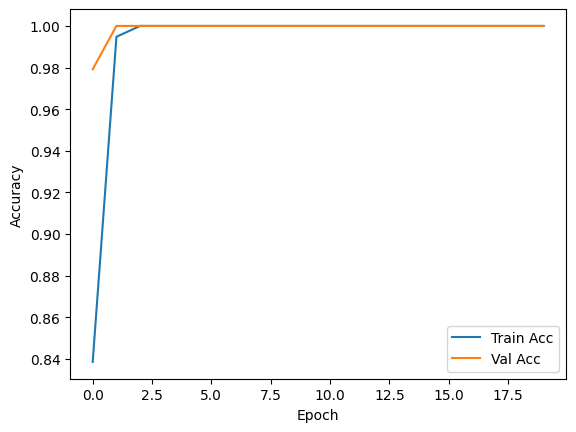

In [20]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()

In [21]:
model.save('day_night_classifier_model.h5')